# 9-7. GARCH 로그 스케일 -- 리샘플링 vs 자체 7분위 구간 비교

**전체 계획** (auto_arima 기반 + GARCH/SV)

1. `9-1`~`9-4`: auto_arima 기반 d 고정, p,q 선택, 원/로그 스케일 구간 비교
2. `9-5`: GARCH·SV 동시최적화 구현과 검증, `9-6`: GARCH 원 스케일
3. **`9-7`: GARCH 로그 스케일** (이 노트북, `9-4` 과정)
4. `9-8`, `9-9`: SV 원/로그 스케일, `9-10`: auto_arima vs GARCH vs SV 종합 비교

**방법**: `100 x log(y)`에 AR(p)+GARCH(1,1) 동시최적화(d=1, AR 차수 p는 로그 시계열에 AR단독 `auto_arima`(AICc)를 적용해 origin마다 선택)를 적합하고, 구간을 `exp`로 되돌려 **원 스케일에서 채점**한다.
- 분위수는 단조변환에 그대로 따라가서 `exp(q/100)`이 원 스케일 분위수다.
- 자체: 로그 스케일 GARCH 정규 구간(원 스케일에서는 비대칭). 리샘플링: 로그 스케일 과거 표준화 오차(500개, 중앙값을 빼서 중심화)에 현재 σ_h를 곱해 점예측에 더한 뒤 `exp`(아래 설명).
- MSE의 점예측은 중앙값 `exp(μ)`이다. GARCH 적합이 실패하면 AR단독 예측으로 대체하고 횟수를 보고한다.

공통 데이터·평가 설정은 `9-1`의 0절을 따른다. 원 스케일 결과(`9-6`)와 4가지 조합으로 비교한다.

**origin 표기**: `origin 35 (훈련 2011Q1~2019Q3, 예측 2019Q4~2020Q3)`처럼 훈련·예측 기간을 함께 적는다.

**리샘플링 방식 -- 필터링된 과거 시뮬레이션(표준화 오차 리샘플링)**: GARCH는 시점마다 σ_h가 달라지는 모델이다. 과거 오차를 그대로 뽑으면 지금 origin의 σ_h가 구간에 반영되지 않으므로, 오차를 σ_h로 표준화해서 뽑는다.
1. 과거 각 origin에서 h단계 오차를 그때의 모델 σ_h로 나눈 **표준화 오차** `z = (실제 - 예측) / σ_h`를 모은다(그 origin 이전에 확정된 것만).
2. z의 **중앙값을 빼서 중심화**한다(두 구간의 중심을 같게 해 구간 방식만 비교하기 위함).
3. 중심화한 z에서 500개를 복원추출한다.
4. **지금 origin의 σ_h를 곱해** 점예측에 더한다: `점예측 + σ_h x (z - 중앙값(z))`.

분산이 일정한 auto_arima(`9-3`, `9-4`)는 σ_h가 시점에 따라 변하지 않아 표준화가 상수배일 뿐이므로 원 오차를 그대로(중심화만) 쓴다. 이 노트북의 '오차 표본 std ÷ σ'는 표준화 오차 z의 표준편차와 같다(1보다 크면 과거에 모델 σ가 실제 오차보다 작았다).


In [1]:
import warnings
warnings.filterwarnings("ignore")
import os
import numpy as np
import pandas as pd
import pmdarima as pm
import properscoring as ps
from arch.univariate import ARX, ZeroMean, GARCH
from scipy import stats

H, MIN_TRAIN, INITIAL_CALIB, ALPHA = 4, 20, 15, 0.10
Z = stats.norm.ppf(1 - ALPHA / 2)
D, N_RESAMPLE, P_MAX, SCALE = 1, 500, 3, 100.0

raw = pd.read_csv("../../data/gold/gold_major_variables.csv")
raw = raw[raw["quarter"].notna()].reset_index(drop=True)
data = raw[["quarter", "X3_l1"]].dropna().reset_index(drop=True)
quarters, vals = data["quarter"].values, data["X3_l1"].values.astype(float)
LOG = SCALE * np.log(vals)
var_std = vals.std()
origins = list(range(MIN_TRAIN, len(vals) - H + 1))
scored_origins = origins[INITIAL_CALIB:]
FIRST = scored_origins[0]
LEVELS = np.array([0.1, 0.2, 0.3, 0.5, 0.7, 0.8, 0.9])


def label(o):
    return f"origin {o} (훈련 {quarters[0]}~{quarters[o - 1]}, 예측 {quarters[o]}~{quarters[o + H - 1]})"


def pinball(q, y, tau):
    return np.where(y >= q, (y - q) * tau, (q - y) * (1 - tau))


def crps7(q7, y):
    return 2 * np.mean([pinball(q7[k], y, LEVELS[k]) for k in range(7)]) / var_std


def to_orig(x):
    return np.exp(np.asarray(x) / SCALE)


def difference(values, d):
    x = np.asarray(values, dtype=float)
    hist = []
    for _ in range(d):
        hist.append(x.copy())
        x = np.diff(x)
    return x, hist


def undiff_mean(diff_fc, hist, d):
    fc = np.asarray(diff_fc, dtype=float)
    for i in reversed(range(d)):
        fc = hist[i][-1] + np.cumsum(fc)
    return fc


def level_sigma(ar_coefs, d, innov_var):
    p = len(ar_coefs)
    psi = np.zeros(H)
    for j in range(H):
        psi[j] = 1.0 if j == 0 else sum(ar_coefs[k] * psi[j - 1 - k] for k in range(min(p, j)))
    for _ in range(d):
        psi = np.cumsum(psi)
    return np.sqrt(np.array([sum(psi[h - i] ** 2 * innov_var[i] for i in range(h + 1)) for h in range(H)]))


def select_p(train):
    # AR단독 auto_arima(정확우도, AICc): d=1 고정, MA 없음, 절편 없음 -> GARCH의 AR 차수로 사용
    m = pm.auto_arima(train, d=D, seasonal=False, start_q=0, max_q=0, max_p=P_MAX, information_criterion="aicc",
                      with_intercept=False, suppress_warnings=True, error_action="ignore")
    return m.order[0], m


def ar_fallback(m):
    fc, conf = m.predict(n_periods=H, return_conf_int=True, alpha=ALPHA)
    return np.asarray(fc), (conf[:, 1] - conf[:, 0]) / (2 * Z)


def garch_forecast(train, p):
    diff_train, hist = difference(train, D)
    am = ZeroMean(diff_train, rescale=False) if p == 0 else ARX(diff_train, lags=p, constant=False, rescale=False)
    am.volatility = GARCH(p=1, q=1)
    res = am.fit(disp="off")
    f = res.forecast(horizon=H, reindex=False)
    ar = [res.params[f"y[{k}]"] for k in range(1, p + 1)]
    fc = undiff_mean(f.mean.values[-1], hist, D)
    sig = level_sigma(ar, D, f.residual_variance.values[-1])
    if not (np.all(np.isfinite(fc)) and np.all(np.isfinite(sig))):
        raise ValueError("non-finite forecast")
    return fc, sig


def model_forecast(series):
    # AR 차수 p는 AR단독 auto_arima가 선택, 적합 실패 시 AR단독 예측으로 대체(대체 횟수는 기록)
    p, m = select_p(series)
    try:
        fc, sig = garch_forecast(series, p)
        return fc, sig, "GARCH", p
    except Exception:
        fc, sig = ar_fallback(m)
        return fc, sig, "AR대체", p


def rng_for(name):
    return np.random.default_rng(int.from_bytes(name.encode(), "little") % (2 ** 32))

print(f"전체 origin {len(origins)}개, 채점 origin {len(scored_origins)}개")
print("첫 채점 origin:", label(FIRST))
print("마지막 채점 origin:", label(scored_origins[-1]))


전체 origin 37개, 채점 origin 22개
첫 채점 origin: origin 35 (훈련 2011Q1~2019Q3, 예측 2019Q4~2020Q3)
마지막 채점 origin: origin 56 (훈련 2011Q1~2024Q4, 예측 2025Q1~2025Q4)


## 1. 로그 스케일에서 두 구간 만들기

각 origin에서 로그 시계열로 p를 고르고 GARCH를 적합해 두 구간을 `exp`로 원 스케일에 되돌린다. d=1은 원 스케일에서 정한 값을 그대로 쓴다.

- 커버리지: 90% 구간을 `exp`로 되돌려 원 스케일 실제값 적중 여부를 본다.
- CRPS(7분위): 되돌린 7분위로 원 스케일에서 계산한다.


In [2]:
CACHE = "../cache/cache_97_garch_log_df.pkl"
SRC_CACHE = "../cache/cache_97_garch_log_src_df.pkl"
if os.path.exists(CACHE) and os.path.exists(SRC_CACHE):
    logres = pd.read_pickle(CACHE)
    src_df = pd.read_pickle(SRC_CACHE)
    print(f"캐시에서 로드: {len(logres)}행")
else:
    rng = rng_for("X3_l1_9-7_garch_log")
    pool = {h: np.array([]) for h in range(1, H + 1)}
    rows, srows = [], []
    for oi, o in enumerate(origins):
        train, actual = LOG[:o], vals[o:o + H]
        fc, sig, src, p = model_forecast(train)
        srows.append({"origin": o, "p": p, "적합": src})
        if oi >= INITIAL_CALIB:
            for h in range(1, H + 1):
                a = actual[h - 1]
                s_h = max(sig[h - 1], 1e-6)                                                   # 100 x log 단위
                samples = fc[h - 1] + s_h * rng.choice(pool[h] - np.median(pool[h]), size=N_RESAMPLE, replace=True)   # 로그 스케일, 오차 중심화
                q7_res = to_orig(np.quantile(samples, LEVELS))
                lo_r, hi_r = to_orig(np.quantile(samples, [ALPHA / 2, 1 - ALPHA / 2]))
                q7_self = to_orig(fc[h - 1] + s_h * stats.norm.ppf(LEVELS))
                lo_n, hi_n = to_orig(fc[h - 1] - Z * s_h), to_orig(fc[h - 1] + Z * s_h)
                med = float(to_orig(fc[h - 1]))
                rows.append({"origin": o, "h": h, "방식": "리샘플링", "적중": float(lo_r <= a <= hi_r) * 100,
                             "MSE": ((a - med) / var_std) ** 2,
                             "CRPS(7분위)": crps7(q7_res, a), "구간폭": (hi_r - lo_r) / var_std, "lo": lo_r, "hi": hi_r, "fc": med, "actual": a,
                             "pool_n": len(pool[h]), "pool_std": s_h * pool[h].std(), "pool_absmax": s_h * np.abs(pool[h]).max()})
                rows.append({"origin": o, "h": h, "방식": "자체", "적중": float(lo_n <= a <= hi_n) * 100,
                             "MSE": ((a - med) / var_std) ** 2,
                             "CRPS(7분위)": crps7(q7_self, a), "구간폭": (hi_n - lo_n) / var_std, "lo": lo_n, "hi": hi_n, "fc": med, "actual": a, "sigma_model": s_h})
        for h in range(1, H + 1):
            pool[h] = np.append(pool[h], (np.log(actual[h - 1]) * SCALE - fc[h - 1]) / max(sig[h - 1], 1e-6))
    logres, src_df = pd.DataFrame(rows), pd.DataFrame(srows).set_index("origin")
    logres.to_pickle(CACHE)
    src_df.to_pickle(SRC_CACHE)
    print(f"계산 완료: {len(logres)}행 (origin {logres['origin'].nunique()}개 x h {H} x 방식 2)")
print("GARCH 적합 대체(AR단독) 횟수 -- 전체 37개 origin 중:", int((src_df["적합"] == "AR대체").sum()), "/ 채점 22개 중:", int((src_df.loc[scored_origins, "적합"] == "AR대체").sum()))
print("선택된 p 분포(채점 22개):", src_df.loc[scored_origins, "p"].value_counts().sort_index().to_dict())


캐시에서 로드: 176행
GARCH 적합 대체(AR단독) 횟수 -- 전체 37개 origin 중: 0 / 채점 22개 중: 0
선택된 p 분포(채점 22개): {1: 15, 2: 7}


## 2. 결과 -- 로그 스케일 22개 origin 전체 평균

22개 origin x h=1~4 = 88개를 방식별로 평균한다. 로그 스케일에서 리샘플링의 과거 오차 표본은 **중앙값을 빼서 중심화**한 뒤 점예측 `exp(μ)`에 더한다. 그래서 두 방식의 점예측이 모두 `exp(μ)`로 같고 MSE도 같다(원 스케일과 같은 구조).

중심화하지 않으면 과거 오차의 치우침만큼 리샘플링 구간 전체가 이동해, 구간 방식의 차이에 점예측 보정 효과가 섞인다. 그래서 원 스케일과 로그 스케일 모두 오차 표본을 중심화한다.


In [3]:
cols = ["적중", "MSE", "CRPS(7분위)", "구간폭"]
log_sum = logres.groupby("방식")[cols].mean().rename(columns={"적중": "커버리지(%)"}).round(3)
display(log_sum)
print("h별 (로그 스케일):")
display(logres.groupby(["방식", "h"])[["적중", "CRPS(7분위)", "구간폭"]].mean().rename(columns={"적중": "커버리지(%)"}).round(3).unstack("방식"))


,커버리지(%),MSE,CRPS(7분위),구간폭
방식,,,,
리샘플링,89.773,1.057,1.066,15.553
자체,73.864,1.057,0.730,5.428


h별 (로그 스케일):


커버리지(%)         CRPS(7분위)            구간폭       
방식    리샘플링      자체      리샘플링     자체    리샘플링     자체
h                                                 
1   81.818  81.818     0.351  0.321   5.049  2.118
2   86.364  77.273     0.864  0.611  16.045  4.147
3   95.455  68.182     1.337  0.878  17.188  6.437
4   95.455  68.182     1.711  1.109  23.928  9.010

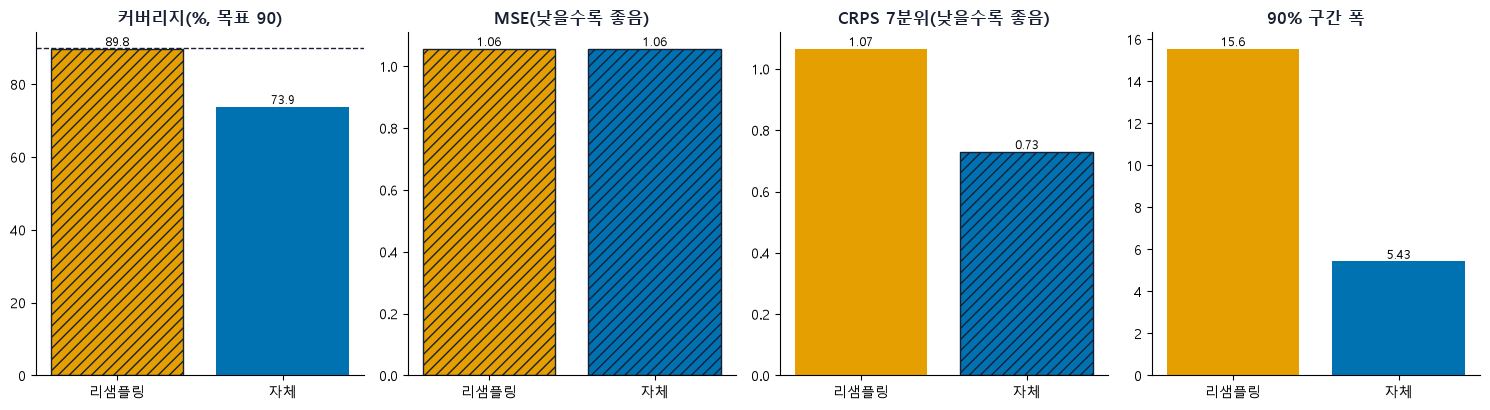

In [4]:
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

colr = {"리샘플링": "#E69F00", "자체": "#0072B2"}
fig, axes = plt.subplots(1, 4, figsize=(15, 4.2))
for ax, (c, t) in zip(axes, [("커버리지(%)", "커버리지(%, 목표 90)"), ("MSE", "MSE(낮을수록 좋음)"), ("CRPS(7분위)", "CRPS 7분위(낮을수록 좋음)"), ("구간폭", "90% 구간 폭")]):
    bars = ax.bar(log_sum.index, log_sum[c], color=[colr[i] for i in log_sum.index])
    if c != "구간폭":
        score = (log_sum[c] - 90).abs() if c.startswith("커버리지") else log_sum[c]
        for b, k in zip(bars, log_sum.index):
            if score[k] <= score.min() + 1e-9:
                b.set_hatch("///")
                b.set_edgecolor("#172033")
    for b in bars:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height(), f"{b.get_height():.3g}", ha="center", va="bottom", fontsize=9)
    if c == "커버리지(%)":
        ax.axhline(90, color="#172033", linestyle="--", linewidth=1)
    ax.set_title(t, fontsize=12, fontweight="bold", color="#172033")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
fig.tight_layout()
plt.show()


## 3. 원 스케일(`9-6`)과 로그 스케일 비교 -- 4가지 조합


In [5]:
orig = pd.read_pickle("../cache/cache_96_garch_orig_df.pkl")
orig_sum = orig.groupby("방식")[cols].mean().rename(columns={"적중": "커버리지(%)"})
tab = pd.concat({"원 스케일": orig_sum, "로그 스케일": log_sum}, names=["스케일", "방식"]).round(3)
mult = (tab.loc["로그 스케일", "구간폭"] / tab.loc["원 스케일", "구간폭"]).round(2)
tab["폭 배율(원 대비)"] = np.nan
tab.loc["로그 스케일", "폭 배율(원 대비)"] = mult.values
display(tab.style.format({"폭 배율(원 대비)": "x{:.2f}"}, na_rep="")
        .set_properties(subset=pd.IndexSlice["로그 스케일", ["구간폭", "폭 배율(원 대비)"]],
                        **{"background-color": "#FFF1D6", "color": "#B45F06", "font-weight": "bold"}))


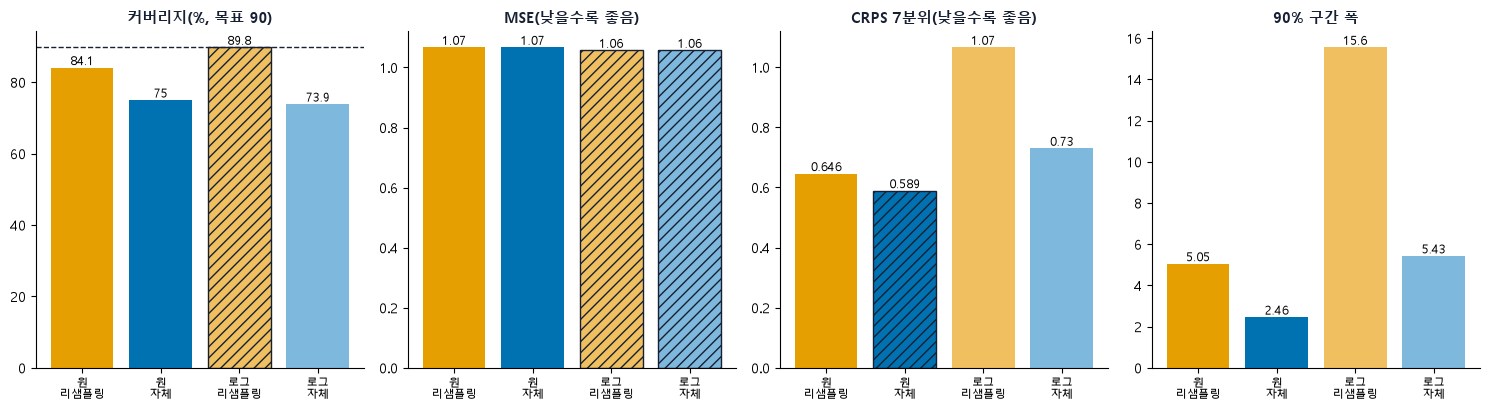

In [6]:
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

combos = [("원 스케일", "리샘플링"), ("원 스케일", "자체"), ("로그 스케일", "리샘플링"), ("로그 스케일", "자체")]
colr4 = {("원 스케일", "리샘플링"): "#E69F00", ("원 스케일", "자체"): "#0072B2", ("로그 스케일", "리샘플링"): "#F0C060", ("로그 스케일", "자체"): "#7FB8DD"}
names = ["원\n리샘플링", "원\n자체", "로그\n리샘플링", "로그\n자체"]
fig, axes = plt.subplots(1, 4, figsize=(15, 4.2))
for ax, (c, t) in zip(axes, [("커버리지(%)", "커버리지(%, 목표 90)"), ("MSE", "MSE(낮을수록 좋음)"), ("CRPS(7분위)", "CRPS 7분위(낮을수록 좋음)"), ("구간폭", "90% 구간 폭")]):
    vals_ = [tab.loc[k, c] for k in combos]
    bars = ax.bar(names, vals_, color=[colr4[k] for k in combos])
    if c != "구간폭":
        sc = np.abs(np.array(vals_) - 90) if c.startswith("커버리지") else np.array(vals_)
        for b, s_ in zip(bars, sc):
            if s_ <= sc.min() + 1e-9:
                b.set_hatch("///")
                b.set_edgecolor("#172033")
    for b in bars:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height(), f"{b.get_height():.3g}", ha="center", va="bottom", fontsize=9)
    if c == "커버리지(%)":
        ax.axhline(90, color="#172033", linestyle="--", linewidth=1)
    ax.set_title(t, fontsize=11, fontweight="bold", color="#172033")
    ax.tick_params(axis="x", labelsize=8)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
fig.tight_layout()
plt.show()


## 4. origin별 추이

로그 스케일의 두 방식을 origin별로 본다(origin당 h=1~4 평균). 원 스케일과의 비교는 위 3절 표와 그림이다.


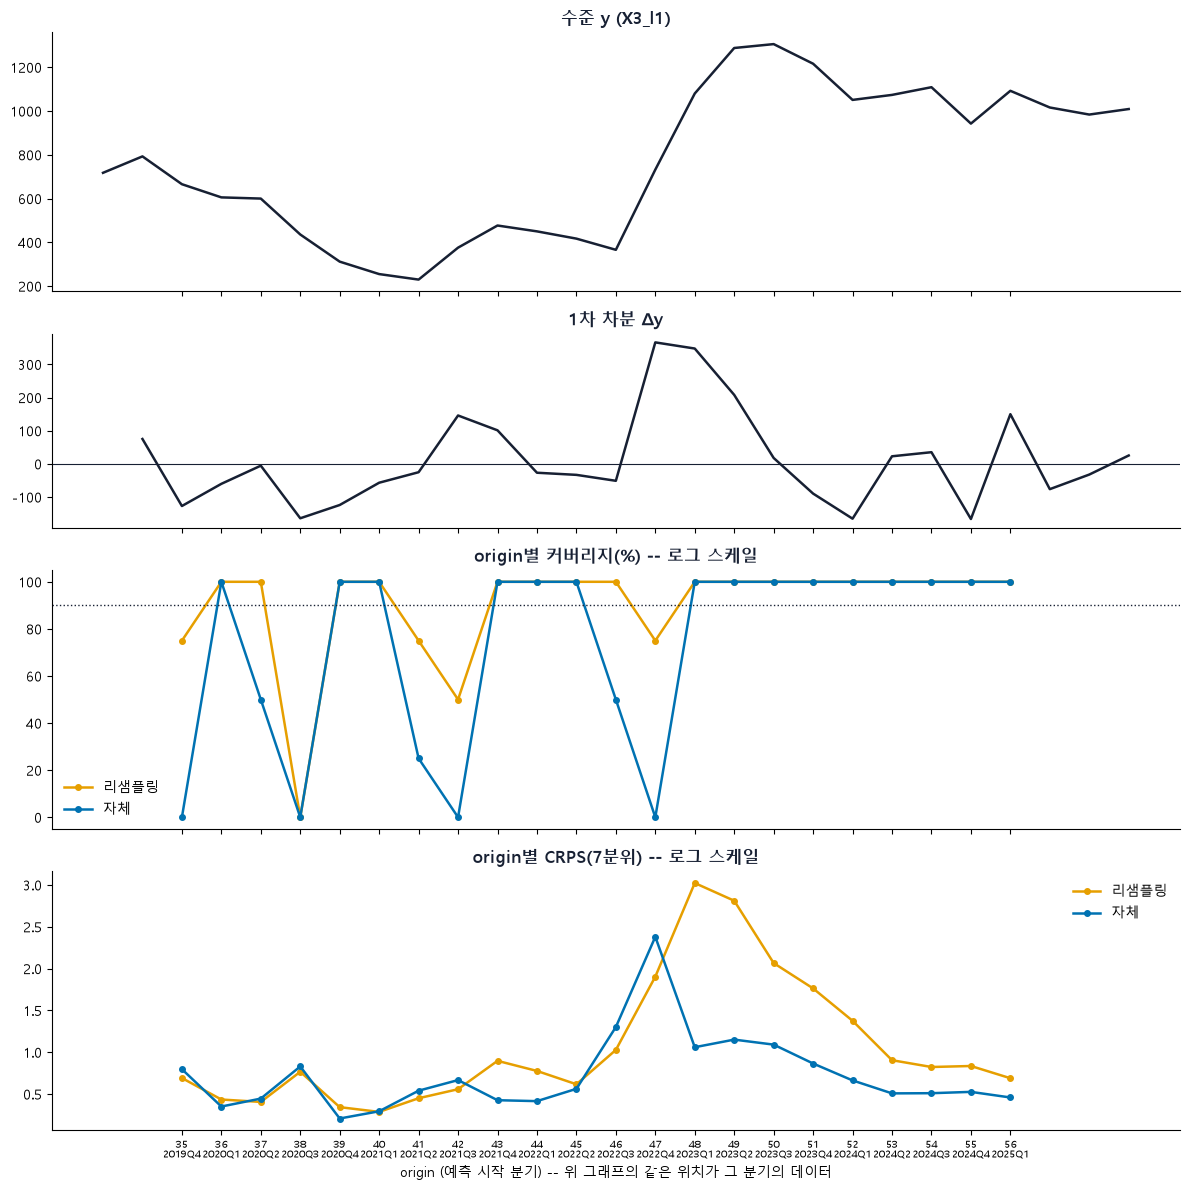

In [7]:
per_log = logres.groupby(["방식", "origin"])[["적중", "CRPS(7분위)"]].mean()
xl = [f"{o}\n{quarters[o]}" for o in scored_origins]
t0 = scored_origins[0] - 2
tt = np.arange(t0, len(vals))
dyv = np.diff(vals)
colr = {"리샘플링": "#E69F00", "자체": "#0072B2"}
fig, axes = plt.subplots(4, 1, figsize=(12, 12), sharex=True, gridspec_kw={"height_ratios": [1.6, 1.2, 1.6, 1.6]})
axes[0].plot(tt, vals[t0:], color="#172033", linewidth=1.8)
axes[0].set_title("수준 y (X3_l1)", fontsize=12, fontweight="bold", color="#172033")
axes[1].plot(tt[1:], dyv[t0:], color="#172033", linewidth=1.8)
axes[1].axhline(0, color="#172033", linewidth=0.8)
axes[1].set_title("1차 차분 Δy", fontsize=12, fontweight="bold", color="#172033")
for ax, c, t in [(axes[2], "적중", "origin별 커버리지(%) -- 로그 스케일"), (axes[3], "CRPS(7분위)", "origin별 CRPS(7분위) -- 로그 스케일")]:
    for name in ["리샘플링", "자체"]:
        ax.plot(scored_origins, per_log.loc[name][c].values, marker="o", ms=4, color=colr[name], linewidth=1.8, label=name)
    ax.set_title(t, fontsize=12, fontweight="bold", color="#172033")
    ax.legend(frameon=False)
axes[2].axhline(90, color="#172033", linestyle=":", linewidth=1)
for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
axes[3].set_xticks(scored_origins)
axes[3].set_xticklabels(xl, fontsize=7)
axes[3].set_xlabel("origin (예측 시작 분기) -- 위 그래프의 같은 위치가 그 분기의 데이터")
fig.tight_layout()
plt.show()


## 5. 결론

**GARCH 로그 스케일에서는 표준화 오차 리샘플링이 커버리지를 90%에 가깝게 올리지만 구간이 2.9배 넓어져 CRPS가 크게 나쁘다. 자체 구간이 낫다.**

| 항목 | 자체 | 리샘플링(표준화) |
|---|---|---|
| 90% 커버리지 | 73.9% | 89.8% |
| CRPS(7분위) | 0.730 | 1.066 |
| 90% 구간 폭 | 5.428 | 15.553 |
| 같은 90%로 맞춘 폭 / 구간점수 | 15.399 / 15.896 | 19.996 / 20.333 |

- 리샘플링이 22개 중 8개 origin에서만 CRPS가 낮고, 급등 이후(origin 47~56)에 특히 불리하다(CRPS 차이 +0.698).
- 같은 90%로 맞춰도 자체가 폭(15.399 vs 19.996)과 구간점수(15.896 vs 20.333)가 낮다. 로그 변환 후 표준화 오차를 σ_h에 곱해 exp로 되돌리면 상방 꼬리가 크게 늘어난다.
- 원 vs 로그: 자체 폭은 원 스케일의 2.2배, 리샘플링 폭은 3.1배다. 점예측 MSE는 로그 1.057, 원 1.067로 거의 같아, 로그 변환이 정확도를 높이지 않으면서 구간만 넓힌다.
- 한계: 22개 origin이 겹치므로 기술적 비교이며, origin 48~56의 α+β≈1이 σ를 부풀린다.


## 6. 두 방식의 차이 분석 (추가 연구)

위 결과에서 리샘플링과 자체 구간의 차이가 **실제로 있는지, 폭 때문인지**를 본다. 검정(부트스트랩·DM)은 쓰지 않고 다음 두 가지로 확인한다.

1. **짝지은 차이**: 같은 origin에서 두 방식의 차이(리샘플링 - 자체)를 구해, 평균이 아니라 origin마다 어떻게 나오는지(몇 개 origin에서 앞서는지, 차이가 한 구간에 몰리는지) 본다.
2. **같은 폭에서 비교**: 커버리지 차이는 구간 폭 차이와 섞여 있다. 두 가지로 폭 효과를 뺀다.
   - **구간 점수(interval score, α=0.10)**: `폭 + (2/α) x 구간을 벗어난 거리`를 `var_std`로 나눈 값이다. 넓어서 커버리지가 오른 것은 폭 항으로 벌점을 받는다. 낮을수록 좋다.
   - **90%를 맞추는 데 필요한 배율 k**: 구간을 점예측(중앙값)을 중심으로 로그 스케일에서 k배로 늘리거나 줄인다(`exp(log(점예측) + k x (log(경계) - log(점예측)))`). 88개 전체의 커버리지가 90%가 되는 최소 k와 그때의 폭을 비교한다. k가 1에 가깝고 폭이 좁을수록 구간의 모양이 잘 맞는 방식이다.


In [8]:
DF = logres.copy()
ALPHA_IS = 0.10
DF["구간점수"] = ((DF["hi"] - DF["lo"]) + (2 / ALPHA_IS) * np.maximum(DF["lo"] - DF["actual"], 0)
              + (2 / ALPHA_IS) * np.maximum(DF["actual"] - DF["hi"], 0)) / var_std

po = DF.groupby(["방식", "origin"])[["CRPS(7분위)", "구간점수", "적중", "구간폭"]].mean()
dif = po.loc["리샘플링"] - po.loc["자체"]        # 리샘플링 - 자체 (origin별)
rows = []
for c, better in [("CRPS(7분위)", "neg"), ("구간점수", "neg"), ("적중", "pos")]:
    d_ = dif[c]
    n_better = int((d_ < -1e-9).sum()) if better == "neg" else int((d_ > 1e-9).sum())
    n_worse = int((d_ > 1e-9).sum()) if better == "neg" else int((d_ < -1e-9).sum())
    rows.append({"지표": c.replace("적중", "커버리지(%)"), "평균 차이": d_.mean(), "중앙값 차이": d_.median(),
                 "리샘플링이 앞선 origin": n_better, "뒤진 origin": n_worse, "같은 origin": len(d_) - n_better - n_worse})
display(pd.DataFrame(rows).set_index("지표").round(3))
print("차이 = 리샘플링 - 자체. CRPS·구간점수는 음수면 리샘플링이 낫고, 커버리지는 양수면 리샘플링이 높다. 22개 origin 기준.")

split = np.where(dif.index <= 46, "origin 35~46 (예측 시작 2022Q3 이전)", "origin 47~56 (2022Q4 이후)")
print("구간별 평균 차이 (리샘플링 - 자체):")
display(dif.groupby(split).mean().rename(columns={"적중": "커버리지(%)"}).round(3))
hdiff = (DF[DF["방식"] == "리샘플링"].groupby("h")[["CRPS(7분위)", "구간점수", "적중"]].mean()
         - DF[DF["방식"] == "자체"].groupby("h")[["CRPS(7분위)", "구간점수", "적중"]].mean())
print("h별 평균 차이 (리샘플링 - 자체):")
display(hdiff.rename(columns={"적중": "커버리지(%)"}).round(3))


,평균 차이,중앙값 차이,리샘플링이 앞선 origin,뒤진 origin,같은 origin
지표,,,,,
CRPS(7분위),0.336,0.183,8,14,0
구간점수,7.672,5.951,7,15,0
커버리지(%),15.909,0.000,6,0,16


차이 = 리샘플링 - 자체. CRPS·구간점수는 음수면 리샘플링이 낫고, 커버리지는 양수면 리샘플링이 높다. 22개 origin 기준.
구간별 평균 차이 (리샘플링 - 자체):


,CRPS(7분위),구간점수,커버리지(%),구간폭
origin 35~46 (예측 시작 2022Q3 이전),0.035,1.927,22.917,4.115
origin 47~56 (2022Q4 이후),0.698,14.565,7.500,17.336


h별 평균 차이 (리샘플링 - 자체):


,CRPS(7분위),구간점수,커버리지(%)
h,,,
1,0.030,2.185,0.000
2,0.253,9.374,9.091
3,0.459,7.103,27.273
4,0.603,12.024,27.273


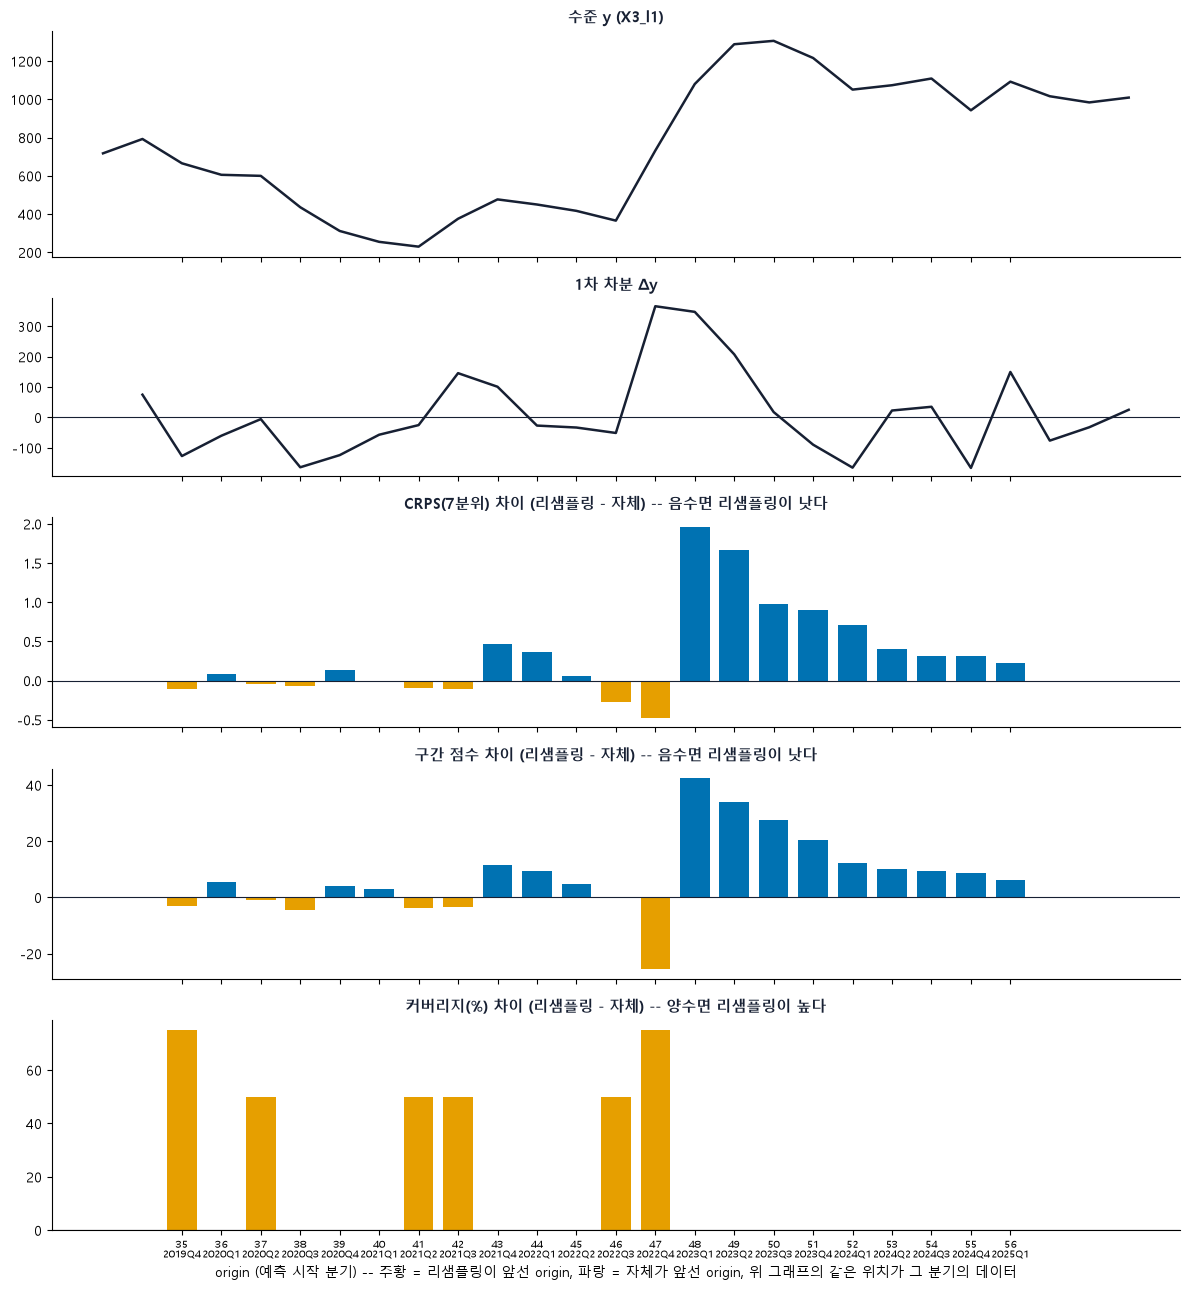

In [9]:
xl2 = [f"{o}\n{quarters[o]}" for o in scored_origins]
t0 = scored_origins[0] - 2
tt = np.arange(t0, len(vals))
dyv = np.diff(vals)
fig, axes = plt.subplots(5, 1, figsize=(12, 13), sharex=True, gridspec_kw={"height_ratios": [1.4, 1.1, 1.3, 1.3, 1.3]})
axes[0].plot(tt, vals[t0:], color="#172033", linewidth=1.8)
axes[0].set_title("수준 y (X3_l1)", fontsize=11, fontweight="bold", color="#172033")
axes[1].plot(tt[1:], dyv[t0:], color="#172033", linewidth=1.8)
axes[1].axhline(0, color="#172033", linewidth=0.8)
axes[1].set_title("1차 차분 Δy", fontsize=11, fontweight="bold", color="#172033")
for ax, c, t, good_neg in [(axes[2], "CRPS(7분위)", "CRPS(7분위) 차이 (리샘플링 - 자체) -- 음수면 리샘플링이 낫다", True),
                           (axes[3], "구간점수", "구간 점수 차이 (리샘플링 - 자체) -- 음수면 리샘플링이 낫다", True),
                           (axes[4], "적중", "커버리지(%) 차이 (리샘플링 - 자체) -- 양수면 리샘플링이 높다", False)]:
    v = dif[c].values
    good = (v < 0) if good_neg else (v > 0)
    ax.bar(scored_origins, v, color=np.where(good, "#E69F00", "#0072B2"), width=0.75)
    ax.axhline(0, color="#172033", linewidth=0.8)
    ax.set_title(t, fontsize=11, fontweight="bold", color="#172033")
for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
axes[4].set_xticks(scored_origins)
axes[4].set_xticklabels(xl2, fontsize=7)
axes[4].set_xlabel("origin (예측 시작 분기) -- 주황 = 리샘플링이 앞선 origin, 파랑 = 자체가 앞선 origin, 위 그래프의 같은 위치가 그 분기의 데이터")
fig.tight_layout()
plt.show()


### 6-1. 같은 폭에서 비교 -- 구간 점수와 90% 도달 배율


In [10]:
LOGMODE = True


def interval_at(g, k):
    fc, lo, hi, a = g["fc"].values, g["lo"].values, g["hi"].values, g["actual"].values
    if LOGMODE:
        lo_k = np.exp(np.log(fc) + k * (np.log(lo) - np.log(fc)))
        hi_k = np.exp(np.log(fc) + k * (np.log(hi) - np.log(fc)))
    else:
        lo_k, hi_k = fc + k * (lo - fc), fc + k * (hi - fc)
    cov = np.mean((a >= lo_k) & (a <= hi_k)) * 100
    width = np.mean(hi_k - lo_k) / var_std
    iscore = np.mean((hi_k - lo_k) + (2 / ALPHA_IS) * np.maximum(lo_k - a, 0) + (2 / ALPHA_IS) * np.maximum(a - hi_k, 0)) / var_std
    return cov, width, iscore


rows = []
for name in ["리샘플링", "자체"]:
    g = DF[DF["방식"] == name]
    cov1, w1, is1 = interval_at(g, 1.0)
    ks = np.linspace(0.2, 8, 1561)
    k90 = next((k for k in ks if interval_at(g, k)[0] >= 90), np.nan)
    cov90, w90, is90 = interval_at(g, k90) if not np.isnan(k90) else (np.nan, np.nan, np.nan)
    rows.append({"방식": name, "원래 커버리지(%)": cov1, "원래 폭": w1, "원래 구간점수": is1,
                 "90% 도달 배율 k": k90, "그때의 폭": w90, "그때의 구간점수": is90})
display(pd.DataFrame(rows).set_index("방식").round(3))
print("k < 1이면 구간을 줄여도 90%에 도달(원래 구간이 넓음), k > 1이면 늘려야 90%에 도달한다. 폭과 구간점수는 var_std로 나눈 값이다.")


,원래 커버리지(%),원래 폭,원래 구간점수,90% 도달 배율 k,그때의 폭,그때의 구간점수
방식,,,,,,
리샘플링,89.773,15.553,16.038,1.115,19.996,20.333
자체,73.864,5.428,8.367,1.785,15.399,15.896


k < 1이면 구간을 줄여도 90%에 도달(원래 구간이 넓음), k > 1이면 늘려야 90%에 도달한다. 폭과 구간점수는 var_std로 나눈 값이다.


### 6-2. 소결

- 기본 비교에서 리샘플링은 CRPS 1.066 대 0.730, 폭 15.553 대 5.428로 모두 나쁘다. 커버리지만 89.8% 대 73.9%로 높다.
- 같은 90%로 맞춘 비교도 자체가 앞선다(폭 15.399 대 19.996, 구간점수 15.896 대 20.333).
- 원 스케일(9-6)보다 격차가 크다. 로그에서 표준화 오차를 exp로 되돌리면 폭이 더 커지기 때문이다.


## 7. 리샘플링 구간이 넓은 이유와 h별 특징

리샘플링의 구간 폭이 자체 구간보다 넓었다. 이유를 다음 가설로 확인하고, h(예측 단계)에 따라 오차와 σ가 어떻게 다른지 본다. 구간을 늘려 90%를 맞추는 배율 k_h는 평가 방법이 아니라 **진단용**으로만 보여 준다(보정한 구간을 평가 대상으로 쓰지 않는다).

- **가설 1**: 모델 σ는 훈련 데이터의 오차에서 추정되는데, 리샘플링은 **실제 out-of-sample 예측오차**를 모아서 만든다. 후자가 크면 리샘플링 구간이 넓다. 오차 표본의 표준편차와 모델 σ의 비율로 확인한다.
- **가설 2**: 큰 충격(급등 시기)의 오차가 오차 표본에 남아 이후 구간을 계속 넓힌다. 오차 표본의 표준편차가 origin에 따라 어떻게 변하는지 본다.
- **h별 확인**: 모델 σ가 h에 따라 커지는 정도가 실제 오차가 커지는 정도와 맞는가.

단위: 오차와 σ는 100 x log 단위(로그 스케일 오차)이다.


In [11]:
DF = logres.copy()
r = DF[DF["방식"] == "리샘플링"].set_index(["origin", "h"])
s = DF[DF["방식"] == "자체"].set_index(["origin", "h"])
sigma = s["sigma_model"]                       # 모델 σ (100 x log 단위(로그 스케일 오차))
err = 100 * (np.log(r['actual']) - np.log(r['fc']))                                    # 점예측 오차 (100 x log 단위(로그 스케일 오차))
z = err / sigma
dd = pd.DataFrame({"오차": err, "σ": sigma, "z": z, "오차표본std": r["pool_std"], "오차표본최대": r["pool_absmax"],
                   "폭비율": (np.log(r['hi']) - np.log(r['lo'])) / (np.log(s['hi']) - np.log(s['lo'])), "표본n": r["pool_n"]})
dd["표본std/σ"] = dd["오차표본std"] / dd["σ"]

print("전체 평균 -- 오차 표본 표준편차 ÷ 모델 σ:", round(dd["표본std/σ"].mean(), 3), " / 구간 폭 비율(리샘플링÷자체):", round(dd["폭비율"].mean(), 3))
print("실제 오차(88개)의 표준편차 ÷ 모델 σ 평균:", round(dd["오차"].std() / dd["σ"].mean(), 3))


전체 평균 -- 오차 표본 표준편차 ÷ 모델 σ: 1.79  / 구간 폭 비율(리샘플링÷자체): 1.963
실제 오차(88개)의 표준편차 ÷ 모델 σ 평균: 1.104


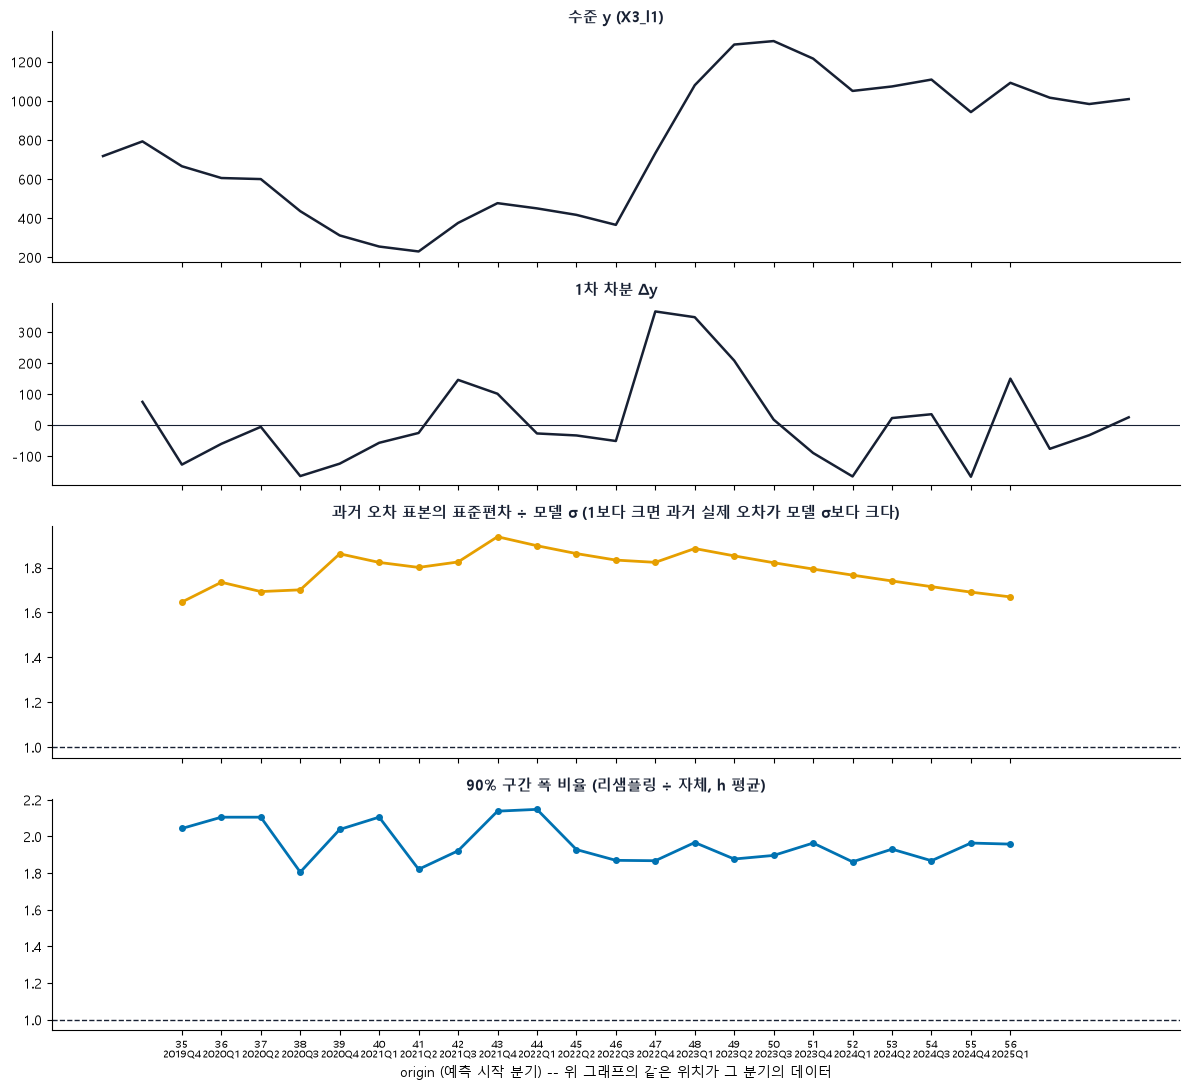

구간별 평균:


,표본std/σ,폭비율
origin 35~46,1.801,2.003
origin 47~56,1.776,1.916


In [12]:
per_o = dd.groupby("origin")[["표본std/σ", "폭비율"]].mean()
xl3 = [f"{o}\n{quarters[o]}" for o in scored_origins]
t0 = scored_origins[0] - 2
tt = np.arange(t0, len(vals))
dyv = np.diff(vals)
fig, axes = plt.subplots(4, 1, figsize=(12, 11), sharex=True, gridspec_kw={"height_ratios": [1.4, 1.1, 1.4, 1.4]})
axes[0].plot(tt, vals[t0:], color="#172033", linewidth=1.8)
axes[0].set_title("수준 y (X3_l1)", fontsize=11, fontweight="bold", color="#172033")
axes[1].plot(tt[1:], dyv[t0:], color="#172033", linewidth=1.8)
axes[1].axhline(0, color="#172033", linewidth=0.8)
axes[1].set_title("1차 차분 Δy", fontsize=11, fontweight="bold", color="#172033")
axes[2].plot(scored_origins, per_o["표본std/σ"].values, marker="o", ms=4, color="#E69F00", linewidth=2)
axes[2].axhline(1, color="#172033", linestyle="--", linewidth=1)
axes[2].set_title("과거 오차 표본의 표준편차 ÷ 모델 σ (1보다 크면 과거 실제 오차가 모델 σ보다 크다)", fontsize=11, fontweight="bold", color="#172033")
axes[3].plot(scored_origins, per_o["폭비율"].values, marker="o", ms=4, color="#0072B2", linewidth=2)
axes[3].axhline(1, color="#172033", linestyle="--", linewidth=1)
axes[3].set_title("90% 구간 폭 비율 (리샘플링 ÷ 자체, h 평균)", fontsize=11, fontweight="bold", color="#172033")
for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
axes[3].set_xticks(scored_origins)
axes[3].set_xticklabels(xl3, fontsize=7)
axes[3].set_xlabel("origin (예측 시작 분기) -- 위 그래프의 같은 위치가 그 분기의 데이터")
fig.tight_layout()
plt.show()

print("구간별 평균:")
split = np.where(per_o.index <= 46, "origin 35~46", "origin 47~56")
display(per_o.groupby(split).mean().round(3))


### 7-1. h별 특징 -- 오차와 σ가 h에 따라 어떻게 커지나

h=1~4마다 실제 오차의 표준편차, 모델 σ의 평균, 둘의 비율, h=1 대비 증가율을 본다. `k_h`는 그 h에서 90%를 맞추는 데 필요한 배율(`|z|`의 90분위 ÷ 1.645)로 **진단용**이다.


,실제 오차 표준편차,모델 σ 평균,오차 표본 표준편차 평균,리샘플링÷자체 폭,k_h (진단),오차÷σ,오차 증가율(h=1=1),σ 증가율(h=1=1)
h,,,,,,,,
1,24.291,21.735,35.328,1.876,2.220,1.118,1.000,1.000
2,42.749,38.249,73.162,2.159,1.987,1.118,1.760,1.760
3,57.278,53.084,99.552,1.987,1.590,1.079,2.358,2.442
4,66.328,66.194,120.590,1.830,1.609,1.002,2.731,3.045


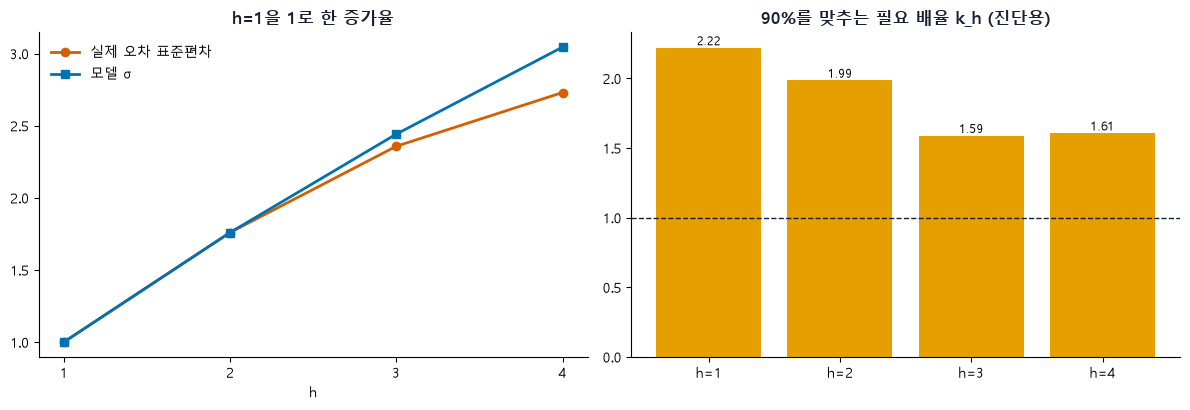

In [13]:
hg = dd.groupby("h")
htab = pd.DataFrame({
    "실제 오차 표준편차": hg["오차"].std(),
    "모델 σ 평균": hg["σ"].mean(),
    "오차 표본 표준편차 평균": hg["오차표본std"].mean(),
    "리샘플링÷자체 폭": hg["폭비율"].mean(),
    "k_h (진단)": hg["z"].apply(lambda x: np.quantile(np.abs(x), 0.9) / Z),
})
htab["오차÷σ"] = htab["실제 오차 표준편차"] / htab["모델 σ 평균"]
htab["오차 증가율(h=1=1)"] = htab["실제 오차 표준편차"] / htab["실제 오차 표준편차"].iloc[0]
htab["σ 증가율(h=1=1)"] = htab["모델 σ 평균"] / htab["모델 σ 평균"].iloc[0]
display(htab.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
hs = htab.index.values
axes[0].plot(hs, htab["오차 증가율(h=1=1)"], marker="o", color="#D55E00", linewidth=2, label="실제 오차 표준편차")
axes[0].plot(hs, htab["σ 증가율(h=1=1)"], marker="s", color="#0072B2", linewidth=2, label="모델 σ")
axes[0].set_xticks(hs)
axes[0].set_title("h=1을 1로 한 증가율", fontsize=12, fontweight="bold", color="#172033")
axes[0].set_xlabel("h")
axes[0].legend(frameon=False)
bars = axes[1].bar([f"h={h}" for h in hs], htab["k_h (진단)"], color="#E69F00")
for b in bars:
    axes[1].text(b.get_x() + b.get_width() / 2, b.get_height(), f"{b.get_height():.2f}", ha="center", va="bottom", fontsize=9)
axes[1].axhline(1, color="#172033", linestyle="--", linewidth=1)
axes[1].set_title("90%를 맞추는 필요 배율 k_h (진단용)", fontsize=12, fontweight="bold", color="#172033")
for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
fig.tight_layout()
plt.show()


### 7-2. 소결

- 과거 표준화 오차의 표준편차(오차 표본 std ÷ σ)가 1.79로, 평가 구간의 실제 오차÷σ(1.10)보다 훨씬 크다. 구간 폭 비율은 1.96이다.
- 급등 전후 비율이 1.80과 1.78로 비슷하다. 급등 시기 오차가 표본에 남아서가 아니라, 표준화 오차 자체가 전반적으로 크다.
- h=1 대비 증가율은 오차 1.00→2.73, σ 1.00→3.05다. k_h(진단)는 2.22, 1.99, 1.59, 1.61이다.
